In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["font.family"] = "Arial"
import seaborn as sns

from additives_microbiota.group_statistics import test_quartile_differences
from additives_microbiota.constants import ADDITIVE_VARS, MIXTURES
from additives_microbiota.plotting import process_string_pretty_vars

### Loading metadata

In [2]:
meta = pd.read_csv("../../data/metadata_files/meta_mixtures.csv", index_col=0)
print(meta.shape)

(975, 201)


## Main Plot

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:7.634e-01 U_stat=2.988e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.712e-03 U_stat=3.183e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.750e-01 U_stat=2.977e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.212e-03 U_stat=3.591e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.847e-04 U_stat=3.347e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.049e-03 U_stat=3.763e+04
thickeners_stabilizers_emulsifiers_gelling_agents_quartile -> shannon_entropy	Significant differences exist. Kruskal-Wallis statistic: 21.134 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1

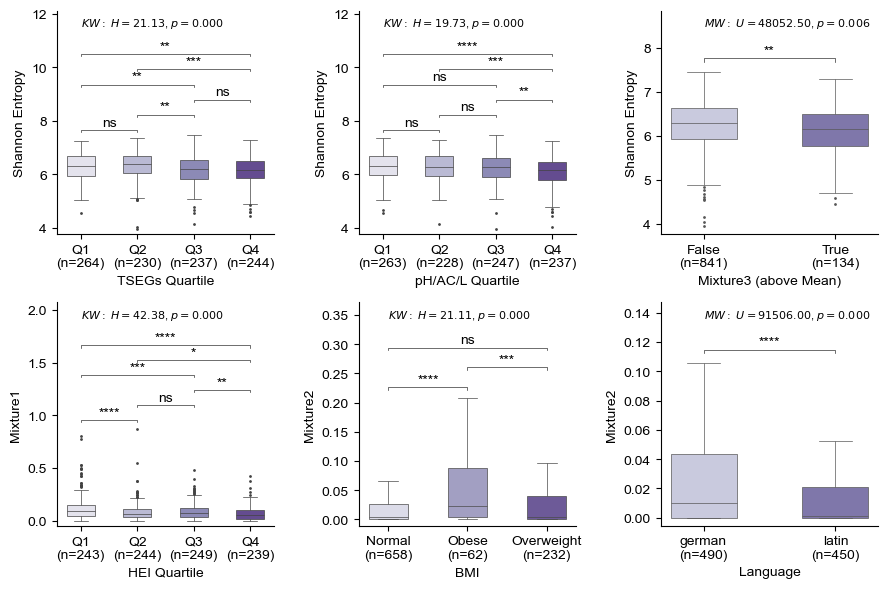

In [3]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))

axes = ax.flatten()

########################################################
var = "thickeners_stabilizers_emulsifiers_gelling_agents"
test_quartile_differences(
    meta,
    var,
    "shannon_entropy",
    extremes=False,
    make_quartile=True,
    palette="Purples",
    ax=axes[0],
    xlabel=process_string_pretty_vars(var) + " Quartile",
)
########################################################
var = "ph_regulators_anti_caking_leavening_agents"
test_quartile_differences(
    meta,
    var,
    "shannon_entropy",
    extremes=False,
    make_quartile=True,
    palette="Purples",
    ax=axes[1],
    xlabel=process_string_pretty_vars(var) + " Quartile",
)
########################################################
a = meta.copy()
var = "Mixture3"

print(a[var].describe(), "\n")
a[var + "_(above_mean)"] = a[var] > a[var].mean()
print(a[var + "_(above_mean)"].value_counts(), "\n")

test_quartile_differences(
    a,
    var + "_(above_mean)",
    "shannon_entropy",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    ax=axes[2],
)
########################################################
test_quartile_differences(
    meta,
    "HEI_Quartile",
    "Mixture1",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    ax=axes[3],
)
########################################################
test_quartile_differences(
    meta[meta["bmi_cat"] != "Underweight"],
    "bmi_cat",
    "Mixture2",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    showfliers=False,
    ax=axes[4],
    xlabel="BMI",
)
########################################################
test_quartile_differences(
    meta[meta["language"].notna()],
    "language",
    "Mixture2",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    showfliers=False,
    ax=axes[5],
)
plt.tight_layout()
sns.despine()

# plt.savefig("../figures/mixtures/mixture_boxplots.png", dpi=300, bbox_inches="tight")

# Spliting the Main plot into two (4 + 1)

In [4]:
# nrows, ncols = 2, 2
# fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6, 6))

# axes = ax.flatten()

# ########################################################
# var = "thickeners_stabilizers_emulsifiers_gelling_agents"

# cmap = plt.cm.Oranges
# colors = [cmap(x) for x in np.linspace(0.05, 0.7, 4)]

# test_quartile_differences(
#     meta,
#     var,
#     "shannon_entropy",
#     extremes=False,
#     make_quartile=True,
#     palette=colors,
#     ax=axes[0],
#     xlabel=process_string_pretty_vars(var) + " Quartile",
#     ylabel="Shannon Diversity",
# )

# ########################################################
# var = "ph_regulators_anti_caking_leavening_agents"

# cmap = plt.cm.Greens
# colors = [cmap(x) for x in np.linspace(0.05, 0.6, 4)]

# test_quartile_differences(
#     meta,
#     var,
#     "shannon_entropy",
#     extremes=False,
#     make_quartile=True,
#     palette=colors,
#     ax=axes[1],
#     xlabel=process_string_pretty_vars(var) + " Quartile",
#     ylabel="Shannon Diversity",
# )
# ########################################################
# ########################################################
# test_quartile_differences(
#     meta,
#     "HEI_Quartile",
#     "Mixture1",
#     extremes=False,
#     palette="Purples",
#     make_quartile=False,
#     ax=axes[2],
# )
# ########################################################
# test_quartile_differences(
#     meta[meta["bmi_cat"] != "Underweight"],
#     "bmi_cat",
#     "Mixture2",
#     extremes=False,
#     palette="Purples",
#     make_quartile=False,
#     showfliers=False,
#     ax=axes[3],
#     xlabel="BMI",
# )

# sns.despine(left=True, right=False)

# for i in range(0, nrows * ncols):
#     axes[i].yaxis.tick_right()
#     axes[i].yaxis.set_label_position("right")
#     axes[i].tick_params(
#         axis="y", which="both", right=True, left=False, length=4, direction="out"
#     )
#     axes[i].yaxis.label.set_rotation(270)
#     axes[i].yaxis.label.set_verticalalignment("bottom")


# plt.tight_layout()


# plt.savefig("../figures/mixtures/mixture_boxplots.png", dpi=300, bbox_inches="tight")

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:7.634e-01 U_stat=2.988e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.712e-03 U_stat=3.183e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.750e-01 U_stat=2.977e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.212e-03 U_stat=3.591e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.847e-04 U_stat=3.347e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.049e-03 U_stat=3.763e+04
thickeners_stabilizers_emulsifiers_gelling_agents_quartile -> shannon_entropy	Significant differences exist. Kruskal-Wallis statistic: 21.134 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1

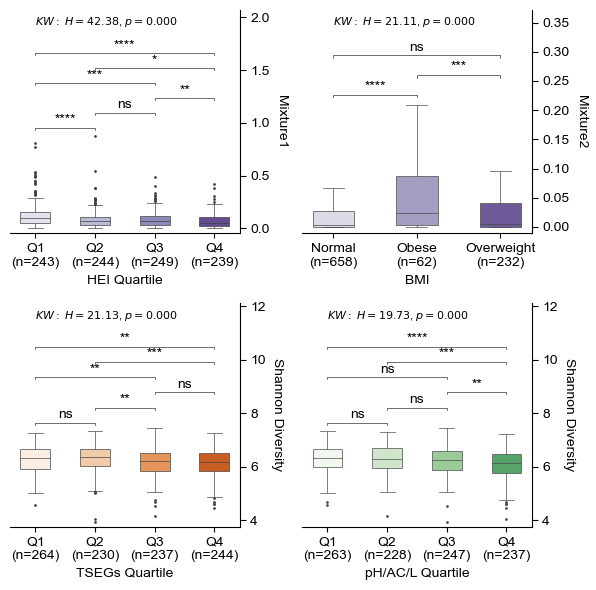

In [5]:
nrows, ncols = 2, 2
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6, 6))

axes = ax.flatten()

########################################################
var = "thickeners_stabilizers_emulsifiers_gelling_agents"

cmap = plt.cm.Oranges
colors = [cmap(x) for x in np.linspace(0.05, 0.7, 4)]

test_quartile_differences(
    meta,
    var,
    "shannon_entropy",
    extremes=False,
    make_quartile=True,
    palette=colors,
    ax=axes[2],
    xlabel=process_string_pretty_vars(var) + " Quartile",
    ylabel="Shannon Diversity",
)

########################################################
var = "ph_regulators_anti_caking_leavening_agents"

cmap = plt.cm.Greens
colors = [cmap(x) for x in np.linspace(0.05, 0.6, 4)]

test_quartile_differences(
    meta,
    var,
    "shannon_entropy",
    extremes=False,
    make_quartile=True,
    palette=colors,
    ax=axes[3],
    xlabel=process_string_pretty_vars(var) + " Quartile",
    ylabel="Shannon Diversity",
)
########################################################
########################################################
test_quartile_differences(
    meta,
    "HEI_Quartile",
    "Mixture1",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    ax=axes[0],
)
########################################################
test_quartile_differences(
    meta[meta["bmi_cat"] != "Underweight"],
    "bmi_cat",
    "Mixture2",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    showfliers=False,
    ax=axes[1],
    xlabel="BMI",
)

sns.despine(left=True, right=False)

for i in range(0, nrows * ncols):
    axes[i].yaxis.tick_right()
    axes[i].yaxis.set_label_position("right")
    axes[i].tick_params(
        axis="y", which="both", right=True, left=False, length=4, direction="out"
    )
    axes[i].yaxis.label.set_rotation(270)
    axes[i].yaxis.label.set_verticalalignment("bottom")


plt.tight_layout()


# plt.savefig("../figures/mixtures/mixture_boxplots.png", dpi=300, bbox_inches="tight")

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:1.882e-05 U_stat=3.629e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.981e-01 U_stat=2.931e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.604e-03 U_stat=3.444e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:2.985e-04 U_stat=3.596e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.607e-02 U_stat=3.285e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.731e-10 U_stat=3.851e+04
HEI_Quartile -> Mixture1	Significant differences exist. Kruskal-Wallis statistic: 42.376 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Normal vs. Obese: Ma

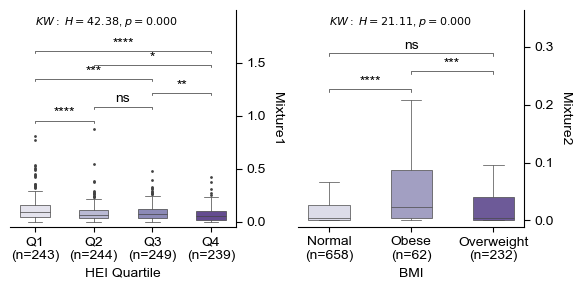

In [ ]:
nrows, ncols = 1, 2
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6, 3))

axes = ax.flatten()

########################################################
########################################################
########################################################
test_quartile_differences(
    meta,
    "HEI_Quartile",
    "Mixture1",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    ax=axes[0],
)
########################################################
test_quartile_differences(
    meta[meta["bmi_cat"] != "Underweight"],
    "bmi_cat",
    "Mixture2",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    showfliers=False,
    ax=axes[1],
    xlabel="BMI",
)

sns.despine(left=True, right=False)

for i in range(0, nrows * ncols):
    axes[i].yaxis.tick_right()
    axes[i].yaxis.set_label_position("right")
    axes[i].tick_params(
        axis="y", which="both", right=True, left=False, length=4, direction="out"
    )
    axes[i].yaxis.label.set_rotation(270)
    axes[i].yaxis.label.set_verticalalignment("bottom")


plt.tight_layout()


plt.savefig("../figures/mixtures/mixture_boxplots.png", dpi=300, bbox_inches="tight")

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:1.882e-05 U_stat=3.629e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.981e-01 U_stat=2.931e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.604e-03 U_stat=3.444e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:2.985e-04 U_stat=3.596e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.607e-02 U_stat=3.285e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.731e-10 U_stat=3.851e+04
HEI_Quartile -> Mixture1	Significant differences exist. Kruskal-Wallis statistic: 42.376 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Normal vs. Obese: Ma

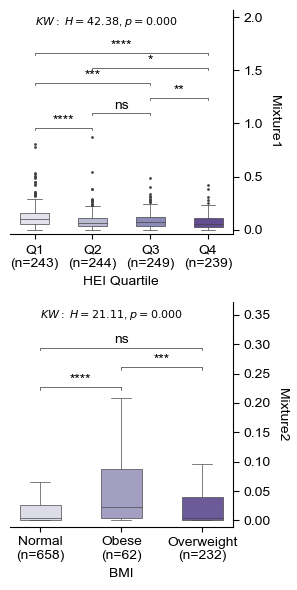

In [15]:
nrows, ncols = 2, 1
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3, 6))

axes = ax.flatten()

########################################################
########################################################
########################################################
test_quartile_differences(
    meta,
    "HEI_Quartile",
    "Mixture1",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    ax=axes[0],
)
########################################################
test_quartile_differences(
    meta[meta["bmi_cat"] != "Underweight"],
    "bmi_cat",
    "Mixture2",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    showfliers=False,
    ax=axes[1],
    xlabel="BMI",
)

sns.despine(left=True, right=False)

for i in range(0, nrows * ncols):
    axes[i].yaxis.tick_right()
    axes[i].yaxis.set_label_position("right")
    axes[i].tick_params(
        axis="y", which="both", right=True, left=False, length=4, direction="out"
    )
    axes[i].yaxis.label.set_rotation(270)
    axes[i].yaxis.label.set_verticalalignment("bottom")


plt.tight_layout()


plt.savefig(
    "../figures/mixtures/mixture_boxplots_vertical.png", dpi=300, bbox_inches="tight"
)

count    975.000000
mean       0.025824
std        0.130003
min        0.000000
25%        0.000000
50%        0.000124
75%        0.011022
max        2.271186
Name: Mixture3, dtype: float64 

Mixture3_(above_mean)
False    841
True     134
Name: count, dtype: int64 

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

False vs. True: Mann-Whitney-Wilcoxon test two-sided, P_val:6.152e-03 U_stat=6.464e+04
Mixture3_(above_mean) -> shannon_entropy	Significant differences exist. Mann-Whitney U statistic: 48052.500 p-value: 0.006


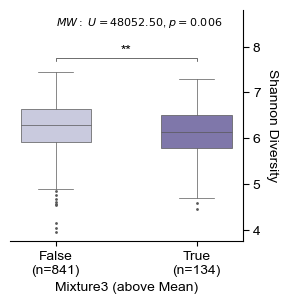

In [8]:
a = meta.copy()
var = "Mixture3"

fig, ax = plt.subplots(figsize=(3, 3))

print(a[var].describe(), "\n")
a[var + "_(above_mean)"] = a[var] > a[var].mean()
print(a[var + "_(above_mean)"].value_counts(), "\n")

test_quartile_differences(
    a,
    var + "_(above_mean)",
    "shannon_entropy",
    extremes=False,
    palette="Purples",
    make_quartile=False,
    ax=ax,
    ylabel="Shannon Diversity",
)

sns.despine(left=True, right=False)

ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")
ax.tick_params(
    axis="y", which="both", right=True, left=False, length=4, direction="out"
)
ax.yaxis.label.set_rotation(270)
ax.yaxis.label.set_verticalalignment("bottom")

plt.savefig(
    "../figures/mixtures/mixture_boxplot_Mixture3.png", dpi=300, bbox_inches="tight"
)

## Other differences

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

german vs. latin: Mann-Whitney-Wilcoxon test two-sided, P_val:3.332e-06 U_stat=1.290e+05
language -> Mixture2	Significant differences exist. Mann-Whitney U statistic: 91506.000 p-value: 0.000


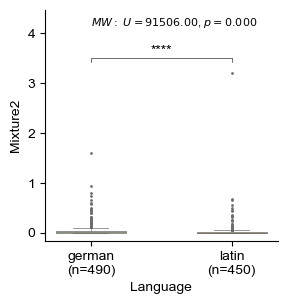

In [9]:
test_quartile_differences(
    meta[meta["language"].notna()],
    "language",
    "Mixture2",
    extremes=False,
    palette="Spectral_r",
    make_quartile=False,
    log_transform=False,
)
sns.despine()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

german vs. latin: Mann-Whitney-Wilcoxon test two-sided, P_val:4.461e-03 U_stat=1.221e+05
language -> total_additive_intake	Significant differences exist. Mann-Whitney U statistic: 98426.000 p-value: 0.004
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

german vs. latin: Mann-Whitney-Wilcoxon test two-sided, P_val:2.510e-01 U_stat=1.150e+05
language -> thickeners_stabilizers_emulsifiers_gelling_agents	No significant differences.
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

german vs. latin: Mann-Whitney-Wilcoxon 

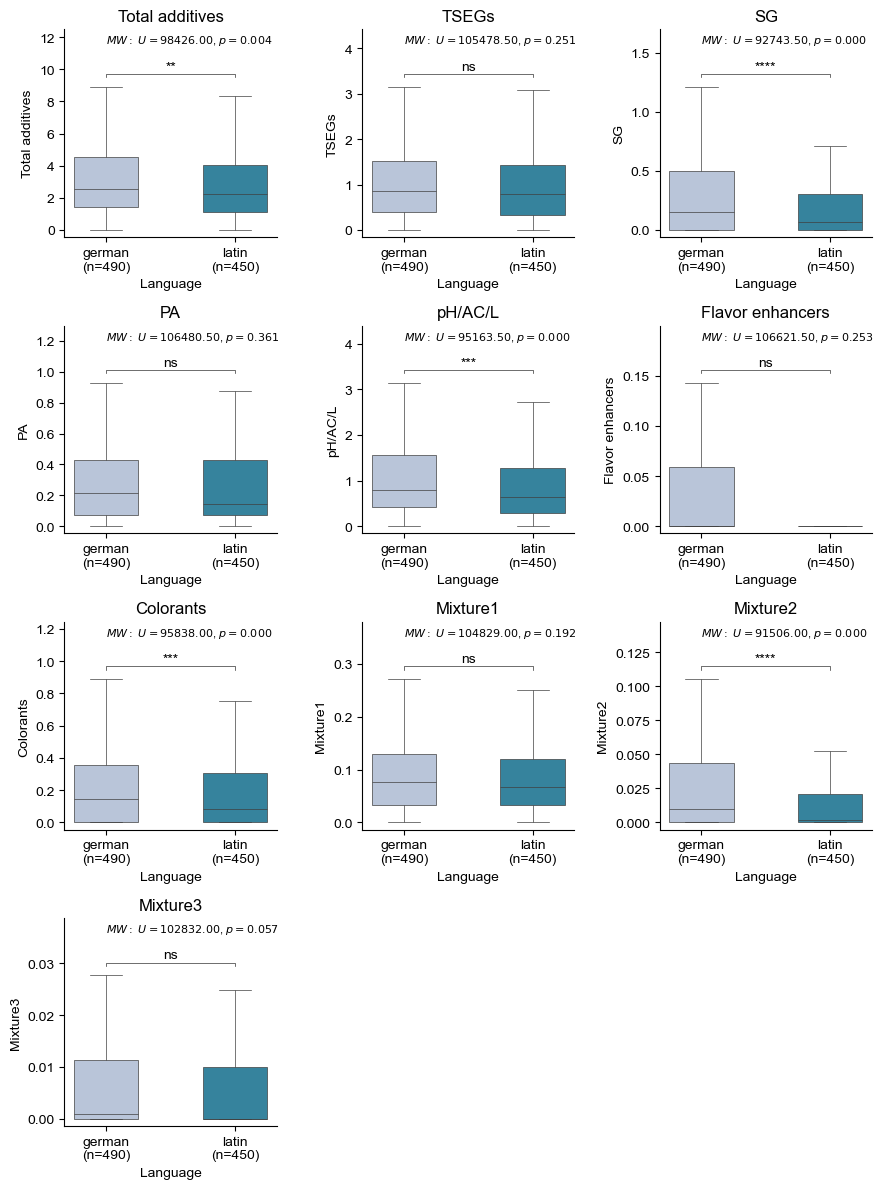

In [10]:
additives_all = ["total_additive_intake"] + ADDITIVE_VARS + MIXTURES
additives_all = [i for i in additives_all if i != "other_additives"]

target_var = "language"

ncols = 3
n = len(additives_all)
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols * 3, nrows * 3))

for idx, additive in enumerate(additives_all):
    row = idx // ncols
    col = idx % ncols

    if nrows == 1:
        ax = axes[col]
    else:
        ax = axes[row, col]

    test_quartile_differences(
        meta[meta[target_var].notna()],
        target_var,
        additive,
        extremes=False,
        palette="PuBuGn",
        make_quartile=False,
        showfliers=False,
        ax=ax,
    )
    ax.set_title(process_string_pretty_vars(additive))

# Remove any unused subplots if additives_all does not fill the grid
for idx in range(n, nrows * ncols):
    row = idx // ncols
    col = idx % ncols
    if nrows == 1:
        fig.delaxes(axes[col])
    else:
        fig.delaxes(axes[row, col])

plt.tight_layout()
sns.despine()

## Physical activities

In [11]:
meta["physical_activities_frequency"].value_counts()

physical_activities_frequency
two_times_per_week       296
three_times_per_week     248
four_times_per_week      215
three_times_per_month     46
once_per_month             7
Name: count, dtype: int64

In [12]:
meta_copy = meta.copy()

physical_activities_monthly_avg = {
    "two_times_per_week": 2 * 4,  # ≈8 per month
    "three_times_per_week": 3 * 4,  # ≈12 per month
    "four_times_per_week": 4 * 4,  # ≈16 per month
    "three_times_per_month": 3,  # 3 per month
    "once_per_month": 1,  # 1 per month
}

physical_activities_weekly_avg = {
    "two_times_per_week": 2,
    "three_times_per_week": 3,
    "four_times_per_week": 4,
    "three_times_per_month": 3 / 4,  # ≈0.75 per week
    "once_per_month": 1 / 4,  # ≈0.25 per week
}

physical_activities_daily_avg = {
    "two_times_per_week": 2 / 7,
    "three_times_per_week": 3 / 7,
    "four_times_per_week": 4 / 7,
    "three_times_per_month": 3 / 28,  # ≈0.11 per day
    "once_per_month": 1 / 28,  # ≈0.036 per day
}

meta_copy["physical_activities_monthly_avg"] = meta_copy[
    "physical_activities_frequency"
].map(physical_activities_monthly_avg)

meta_copy["physical_activities_weekly_avg"] = meta_copy[
    "physical_activities_frequency"
].map(physical_activities_weekly_avg)

meta_copy["physical_activities_daily_avg"] = meta_copy[
    "physical_activities_frequency"
].map(physical_activities_daily_avg)

print(
    meta_copy[
        [
            "physical_activities_monthly_avg",
            "physical_activities_weekly_avg",
            "physical_activities_daily_avg",
        ]
        + [
            "shannon_entropy",
            "faith_pd",
            "observed_features",
            "pielou_evenness",
        ]
        + MIXTURES
    ]
    .corr()["physical_activities_monthly_avg"]
    .sort_values(ascending=False)
)


# meta_copy["physical_activities_frequency_category"] = meta_copy[
#     "physical_activities_weekly_avg"
# ].map(lambda x: "High" if x >= 3 else "Medium" if x >= 1 else "Low")

meta_copy["physical_activities_frequency_category"] = meta_copy[
    "physical_activities_weekly_avg"
].map(
    lambda x: (
        "High\n(>3 times/week)"
        if x >= 3
        else "Moderate\n(2 times/week)" if x >= 1 else "Low\n(<1 time/week)"
    )
)
meta_copy["physical_activities_frequency_category"] = pd.Categorical(
    meta_copy["physical_activities_frequency_category"],
    categories=[
        "Low\n(<1 time/week)",
        "Moderate\n(2 times/week)",
        "High\n(>3 times/week)",
    ],
    ordered=True,
)

print(meta_copy["physical_activities_frequency_category"].value_counts())

physical_activities_daily_avg      1.000000
physical_activities_monthly_avg    1.000000
physical_activities_weekly_avg     1.000000
pielou_evenness                    0.069711
Mixture3                           0.041822
shannon_entropy                    0.027938
Mixture1                           0.008761
faith_pd                          -0.000236
observed_features                 -0.026176
Mixture2                          -0.034252
Name: physical_activities_monthly_avg, dtype: float64
physical_activities_frequency_category
High\n(>3 times/week)       463
Moderate\n(2 times/week)    296
Low\n(<1 time/week)         216
Name: count, dtype: int64


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Low
(<1 time/week) vs. Moderate
(2 times/week): Mann-Whitney-Wilcoxon test two-sided, P_val:7.178e-02 U_stat=2.922e+04
Moderate
(2 times/week) vs. High
(>3 times/week): Mann-Whitney-Wilcoxon test two-sided, P_val:2.023e-01 U_stat=6.497e+04
Low
(<1 time/week) vs. High
(>3 times/week): Mann-Whitney-Wilcoxon test two-sided, P_val:2.585e-03 U_stat=4.328e+04
physical_activities_frequency_category -> Mixture3	Significant differences exist. Kruskal-Wallis statistic: 9.263 p-value: 0.010


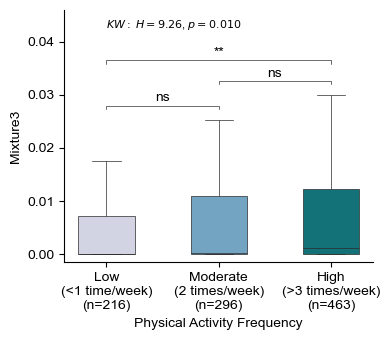

In [13]:
target_var = "physical_activities_frequency_category"

fig, ax = plt.subplots(ncols=1, figsize=(4, 3.5))


test_quartile_differences(
    meta_copy[meta_copy[target_var].notna()],
    target_var,
    "Mixture3",
    extremes=False,
    palette="PuBuGn",
    make_quartile=False,
    showfliers=False,
    ax=ax,
    xlabel="Physical Activity Frequency",
)

# test_quartile_differences(
#     meta_copy[meta_copy[target_var].notna()],
#     target_var,
#     "shannon_entropy",
#     extremes=False,
#     palette="PuBuGn",
#     make_quartile=False,
#     showfliers=True,
# )

plt.tight_layout()
sns.despine()

plt.savefig(
    "../figures/mixtures/mixture_boxplot_Mixture3_physical_activity_frequency.png",
    dpi=300,
    bbox_inches="tight",
)